In [28]:
from google.colab import files

uploaded = files.upload()

Saving credit_card_customer_churn_dataset.csv to credit_card_customer_churn_dataset (1).csv


In [29]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sqlite3
import seaborn as sns

In [30]:
df = pd.read_csv('credit_card_customer_churn_dataset.csv')

In [31]:
df.head()

,customer_id,age,gender,marital_status,education_level,employment_status,income,city,credit_score,account_age_months,...,support_satisfaction,reward_points,offers_received,offers_redeemed,financial_stress_score,engagement_score,customer_value_score,churn_risk_score,churn_probability,churned
0,CUST-0000001,50,Male,Divorced,Bachelor,Employed,31679.55,San Diego,685,151,...,4.1,728,3,1,50.33,74.89,54.35,13.00,0.1300,0
1,CUST-0000002,42,Female,Married,Bachelor,Self-Employed,83618.66,Los Angeles,732,81,...,3.3,13537,3,2,17.70,85.36,99.34,4.30,0.0430,0
2,CUST-0000003,52,Male,Married,Bachelor,Self-Employed,134295.30,Phoenix,777,41,...,3.2,4671,4,2,15.67,74.81,30.56,3.32,0.0332,0
3,CUST-0000004,63,Female,Married,Bachelor,Employed,100983.46,New York,708,54,...,3.1,12694,4,0,13.13,47.55,80.07,19.30,0.1930,0
4,CUST-0000005,40,Male,Married,Bachelor,Employed,89736.89,Other,664,95,...,4.5,37007,1,1,44.25,58.71,100.00,15.10,0.1510,0


In [32]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 40 columns):
 #   Column                      Non-Null Count   Dtype  
---  ------                      --------------   -----  
 0   customer_id                 100000 non-null  object 
 1   age                         100000 non-null  int64  
 2   gender                      100000 non-null  object 
 3   marital_status              100000 non-null  object 
 4   education_level             100000 non-null  object 
 5   employment_status           100000 non-null  object 
 6   income                      100000 non-null  float64
 7   city                        100000 non-null  object 
 8   credit_score                100000 non-null  int64  
 9   account_age_months          100000 non-null  int64  
 10  card_type                   100000 non-null  object 
 11  credit_limit                100000 non-null  float64
 12  annual_fee                  100000 non-null  int64  
 13  interest_rate  

In [33]:
df[['churned']]

,churned
0,0
1,0
2,0
3,0
4,0
...,...
99995,1
99996,0
99997,0
99998,0


In [34]:
df.tail()

,customer_id,age,gender,marital_status,education_level,employment_status,income,city,credit_score,account_age_months,...,support_satisfaction,reward_points,offers_received,offers_redeemed,financial_stress_score,engagement_score,customer_value_score,churn_risk_score,churn_probability,churned
99995,CUST-0099996,41,Male,Widowed,Bachelor,Retired,15000.00,Houston,726,9,...,4.1,1553,2,0,30.57,41.15,38.36,38.13,0.3813,1
99996,CUST-0099997,36,Female,Married,Bachelor,Employed,27693.04,New York,669,45,...,3.8,1646,4,2,35.87,78.59,42.17,9.85,0.0985,0
99997,CUST-0099998,49,Female,Married,High School,Retired,62106.99,San Diego,653,43,...,2.8,4038,3,1,30.89,72.45,42.23,8.93,0.0893,0
99998,CUST-0099999,41,Female,Married,Associate,Employed,97903.38,Other,625,35,...,3.0,4907,3,0,14.24,61.02,46.76,3.72,0.0372,0
99999,CUST-0100000,45,Female,Married,Master,Employed,144124.87,Other,683,47,...,2.8,22770,3,3,32.09,84.86,100.00,4.53,0.0453,0


In [35]:
df.isnull().sum()

,0
customer_id,0
age,0
gender,0
marital_status,0
education_level,0
employment_status,0
income,0
city,0
credit_score,0
account_age_months,0


In [36]:
(df.isnull().sum() / len(df) * 100).round(2)

,0
customer_id,0.0
age,0.0
gender,0.0
marital_status,0.0
education_level,0.0
employment_status,0.0
income,0.0
city,0.0
credit_score,0.0
account_age_months,0.0


In [37]:
df[df.isnull().any(axis=1)]

,customer_id,age,gender,marital_status,education_level,employment_status,income,city,credit_score,account_age_months,...,support_satisfaction,reward_points,offers_received,offers_redeemed,financial_stress_score,engagement_score,customer_value_score,churn_risk_score,churn_probability,churned


In [38]:
df[df.isnull().any(axis=1)].shape

(0, 40)

In [39]:
df[df.isnull().any(axis=1)].isnull().sum(axis=1)

,0


In [40]:
df.dropna(inplace = True)

In [41]:
df.isnull().sum()

,0
customer_id,0
age,0
gender,0
marital_status,0
education_level,0
employment_status,0
income,0
city,0
credit_score,0
account_age_months,0


In [42]:
df.shape

(100000, 40)

In [43]:
df.duplicated().sum()

np.int64(0)

In [44]:
df.describe()

,age,income,credit_score,account_age_months,credit_limit,annual_fee,interest_rate,num_products,has_loan,has_savings_account,...,support_satisfaction,reward_points,offers_received,offers_redeemed,financial_stress_score,engagement_score,customer_value_score,churn_risk_score,churn_probability,churned
count,100000.000000,100000.000000,100000.000000,100000.00000,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000,100000.00000,...,100000.000000,100000.000000,100000.000000,100000.00000,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000
mean,43.634520,80669.829262,689.076850,42.43691,17877.790000,74.029000,16.676273,1.798710,0.350500,0.59842,...,3.454744,7017.855930,3.001990,1.05078,28.221484,65.245465,50.019722,19.459803,0.194598,0.194580
std,12.720601,52343.665518,78.320767,41.95538,14826.138205,117.268259,2.725795,0.870379,0.477129,0.49022,...,0.890964,7494.044255,1.729241,1.02474,15.265985,15.570877,23.455054,21.883271,0.218833,0.395879
min,18.000000,15000.000000,344.000000,1.00000,1000.000000,0.000000,8.990000,1.000000,0.000000,0.00000,...,1.000000,40.000000,0.000000,0.00000,0.000000,10.010000,0.770000,0.060000,0.000600,0.000000
25%,35.000000,44670.952500,636.000000,12.00000,7700.000000,0.000000,14.790000,1.000000,0.000000,0.00000,...,2.900000,2323.000000,2.000000,0.00000,17.650000,54.090000,30.960000,4.280000,0.042800,0.000000
50%,44.000000,67196.330000,690.000000,30.00000,13400.000000,50.000000,16.660000,2.000000,0.000000,1.00000,...,3.600000,4635.500000,3.000000,1.00000,26.040000,64.550000,46.040000,10.580000,0.105800,0.000000
75%,52.000000,101188.717500,744.000000,58.00000,23100.000000,150.000000,18.530000,2.000000,1.000000,1.00000,...,4.100000,8905.000000,4.000000,2.00000,36.200000,75.750000,65.780000,26.120000,0.261200,0.000000
max,85.000000,350000.000000,850.000000,490.00000,75000.000000,450.000000,28.520000,4.000000,1.000000,1.00000,...,5.000000,87409.000000,13.000000,8.00000,100.000000,100.000000,100.000000,99.940000,0.999400,1.000000


In [45]:
df.describe(include='object')

,customer_id,gender,marital_status,education_level,employment_status,city,card_type
count,100000,100000,100000,100000,100000,100000,100000
unique,100000,3,4,5,5,10,4
top,CUST-0000001,Female,Married,Bachelor,Employed,Other,Standard
freq,1,49193,48091,39937,62082,42047,45048


In [46]:
categorical_columns = df.select_dtypes(include='object').columns

for col in categorical_columns:
    print("\nColumn:", col)
    print(df[col].unique())


Column: customer_id
['CUST-0000001' 'CUST-0000002' 'CUST-0000003' ... 'CUST-0099998'
 'CUST-0099999' 'CUST-0100000']

Column: gender
['Male' 'Female' 'Other']

Column: marital_status
['Divorced' 'Married' 'Single' 'Widowed']

Column: education_level
['Bachelor' 'High School' 'Master' 'Associate' 'Doctorate']

Column: employment_status
['Employed' 'Self-Employed' 'Retired' 'Unemployed' 'Student']

Column: city
['San Diego' 'Los Angeles' 'Phoenix' 'New York' 'Other' 'Houston'
 'San Antonio' 'Chicago' 'Philadelphia' 'Dallas']

Column: card_type
['Standard' 'Gold' 'Silver' 'Platinum']


In [47]:
binary_columns = [
    'has_loan',
    'has_savings_account',
    'churned'
]
for col in binary_columns:
   print(col,df[col].unique())

has_loan [0 1]
has_savings_account [1 0]
churned [0 1]


In [48]:
count_columns = [
    'payment_delay_count',
    'app_logins_monthly',
    'website_visits_monthly',
    'customer_service_calls',
    'complaints_count',
    'reward_points',
    'offers_received',
    'offers_redeemed'
]

for col in count_columns:
    print(col, df[col].unique()[:10])

payment_delay_count [1 0 2 4 3 5 6 7 8 9]
app_logins_monthly [ 8 20 12 10  5  9 11 17 16 13]
website_visits_monthly [ 4  5  3  7  6  9  2 10  8 12]
customer_service_calls [ 1  0  2  5  7  4  3  6  8 12]
complaints_count [0 1 2 3 4 6 7 8 5 9]
reward_points [  728 13537  4671 12694 37007  6774 12100 11957  5720  6342]
offers_received [ 3  4  1  5  0  2  6  7  8 10]
offers_redeemed [1 2 0 3 4 5 7 6 8]


In [49]:
integer_columns = [
    'churned',
    'payment_delay_count',
    'app_logins_monthly',
    'website_visits_monthly',
    'customer_service_calls',
    'complaints_count',
    'reward_points',
    'offers_received',
    'offers_redeemed'
]
df[integer_columns] = df[integer_columns].astype('int64')

In [50]:
df[integer_columns].dtypes

,0
churned,int64
payment_delay_count,int64
app_logins_monthly,int64
website_visits_monthly,int64
customer_service_calls,int64
complaints_count,int64
reward_points,int64
offers_received,int64
offers_redeemed,int64


In [51]:
numerical_columns = df.select_dtypes(include=['int64', 'float64']).columns

print(numerical_columns)

Index(['age', 'income', 'credit_score', 'account_age_months', 'credit_limit',
       'annual_fee', 'interest_rate', 'num_products', 'has_loan',
       'has_savings_account', 'monthly_spending', 'avg_transaction_amount',
       'monthly_transactions', 'online_transactions',
       'international_transactions', 'cash_withdrawals', 'utilization_ratio',
       'payment_delay_count', 'late_payment_amount', 'app_logins_monthly',
       'website_visits_monthly', 'customer_service_calls', 'complaints_count',
       'support_satisfaction', 'reward_points', 'offers_received',
       'offers_redeemed', 'financial_stress_score', 'engagement_score',
       'customer_value_score', 'churn_risk_score', 'churn_probability',
       'churned'],
      dtype='object')


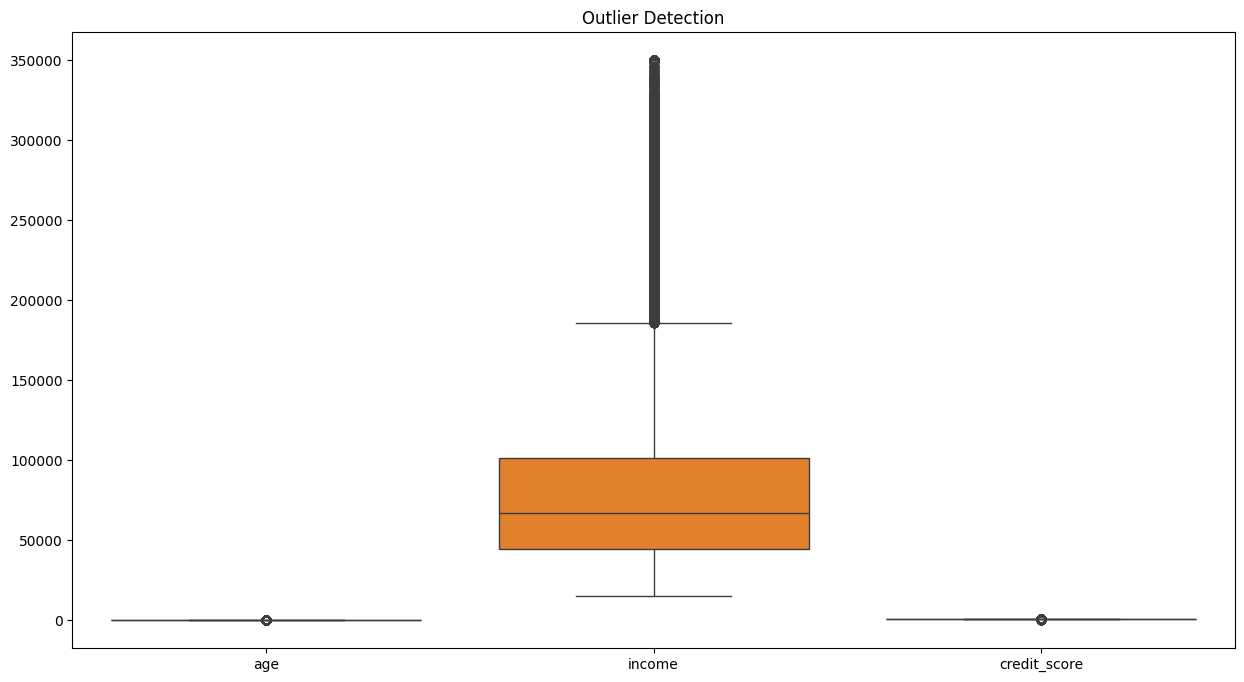

In [52]:
plt.figure(figsize=(15, 8))

sns.boxplot(data=df[['age', 'income', 'credit_score']])

plt.title('Outlier Detection')
plt.show()

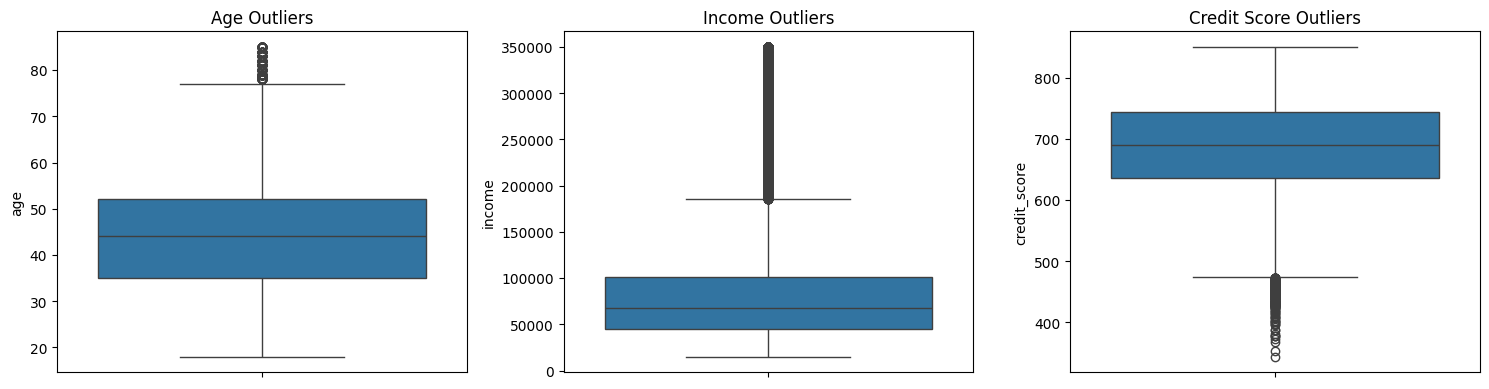

In [53]:
plt.figure(figsize=(15, 4))

plt.subplot(1, 3, 1)
sns.boxplot(y=df['age'])
plt.title('Age Outliers')

plt.subplot(1, 3, 2)
sns.boxplot(y=df['income'])
plt.title('Income Outliers')

plt.subplot(1, 3, 3)
sns.boxplot(y=df['credit_score'])
plt.title('Credit Score Outliers')

plt.tight_layout()
plt.show()

In [54]:
columns = ['age', 'income', 'credit_score']

for col in columns:

    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)

    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    outliers = df[(df[col] < lower) | (df[col] > upper)]

    print("\nColumn:", col)
    print("Q1:", Q1)
    print("Q3:", Q3)
    print("IQR:", IQR)
    print("Lower Bound:", lower)
    print("Upper Bound:", upper)
    print("Number of Outliers:", len(outliers))


Column: age
Q1: 35.0
Q3: 52.0
IQR: 17.0
Lower Bound: 9.5
Upper Bound: 77.5
Number of Outliers: 431

Column: income
Q1: 44670.9525
Q3: 101188.7175
IQR: 56517.765
Lower Bound: -40105.69499999999
Upper Bound: 185965.365
Number of Outliers: 4806

Column: credit_score
Q1: 636.0
Q3: 744.0
IQR: 108.0
Lower Bound: 474.0
Upper Bound: 906.0
Number of Outliers: 328


In [55]:
Q1 = df['credit_score'].quantile(0.25)
Q3 = df['credit_score'].quantile(0.75)

IQR = Q3 - Q1

lower = Q1 - 1.5 * IQR
upper = Q3 + 1.5 * IQR

outliers = df[
    (df['credit_score'] < lower) |
    (df['credit_score'] > upper)
]

print("Credit Score Outliers:", len(outliers))
print("Minimum Outlier:", outliers['credit_score'].min())
print("Maximum Outlier:", outliers['credit_score'].max())

Credit Score Outliers: 328
Minimum Outlier: 344
Maximum Outlier: 473


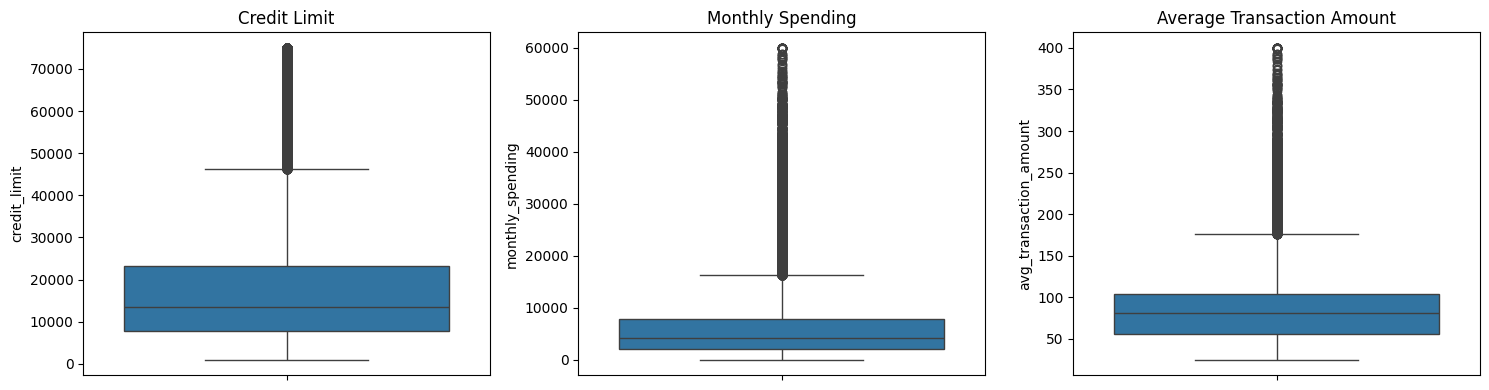

In [56]:
plt.figure(figsize=(15, 4))

plt.subplot(1, 3, 1)
sns.boxplot(y=df['credit_limit'])
plt.title('Credit Limit')

plt.subplot(1, 3, 2)
sns.boxplot(y=df['monthly_spending'])
plt.title('Monthly Spending')

plt.subplot(1, 3, 3)
sns.boxplot(y=df['avg_transaction_amount'])
plt.title('Average Transaction Amount')

plt.tight_layout()
plt.show()

In [57]:
columns = [
    'credit_limit',
    'monthly_spending',
    'avg_transaction_amount'
]

for col in columns:

    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)

    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    outliers = df[
        (df[col] < lower) |
        (df[col] > upper)
    ]

    print("\nColumn:", col)
    print("Q1:", Q1)
    print("Q3:", Q3)
    print("IQR:", IQR)
    print("Lower Bound:", lower)
    print("Upper Bound:", upper)
    print("Number of Outliers:", len(outliers))


Column: credit_limit
Q1: 7700.0
Q3: 23100.0
IQR: 15400.0
Lower Bound: -15400.0
Upper Bound: 46200.0
Number of Outliers: 5908

Column: monthly_spending
Q1: 2073.8050000000003
Q3: 7773.455
IQR: 5699.65
Lower Bound: -6475.669999999998
Upper Bound: 16322.929999999998
Number of Outliers: 6757

Column: avg_transaction_amount
Q1: 56.307500000000005
Q3: 104.31
IQR: 48.0025
Lower Bound: -15.696249999999992
Upper Bound: 176.31375
Number of Outliers: 1905


In [58]:
columns = [
    'late_payment_amount',
    'cash_withdrawals',
    'utilization_ratio'
]

for col in columns:

    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)

    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    outliers = df[
        (df[col] < lower) |
        (df[col] > upper)
    ]

    print("\nColumn:", col)
    print("Lower Bound:", lower)
    print("Upper Bound:", upper)
    print("Number of Outliers:", len(outliers))


Column: late_payment_amount
Lower Bound: -22.5
Upper Bound: 37.5
Number of Outliers: 15431

Column: cash_withdrawals
Lower Bound: -3.0
Upper Bound: 5.0
Number of Outliers: 147

Column: utilization_ratio
Lower Bound: -0.11149999999999999
Upper Bound: 0.8525
Number of Outliers: 650


In [59]:
df['late_payment_amount'].describe()

,late_payment_amount
count,100000.000000
mean,19.710776
std,50.401669
min,0.000000
25%,0.000000
50%,0.000000
75%,15.000000
max,500.000000


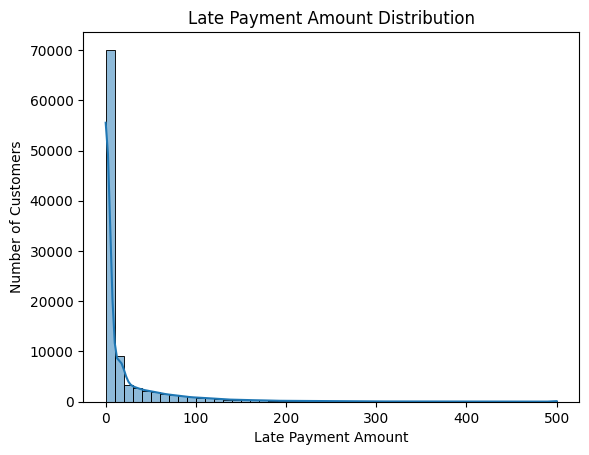

In [60]:
sns.histplot(df['late_payment_amount'], bins=50, kde=True)

plt.title('Late Payment Amount Distribution')
plt.xlabel('Late Payment Amount')
plt.ylabel('Number of Customers')

plt.show()

In [61]:
df.shape

(100000, 40)

In [62]:
df['utilization_ratio'].describe()

,utilization_ratio
count,100000.000000
mean,0.378698
std,0.172453
min,0.010000
25%,0.250000
50%,0.361000
75%,0.491000
max,0.990000


In [63]:
print("Dataset Shape:", df.shape)

print("\nTotal Missing Values:")
print(df.isnull().sum().sum())

print("\nDuplicate Rows:")
print(df.duplicated().sum())

print("\nChurn Distribution:")
print(df['churned'].value_counts())

Dataset Shape: (100000, 40)

Total Missing Values:
0

Duplicate Rows:
0

Churn Distribution:
churned
0    80542
1    19458
Name: count, dtype: int64


In [64]:
total_customers = len(df)

churned_customers = df['churned'].sum()

active_customers = total_customers - churned_customers

churn_rate = (churned_customers / total_customers) * 100

print("Total Customers:", total_customers)
print("Churned Customers:", churned_customers)
print("Active Customers:", active_customers)
print("Churn Rate:", round(churn_rate, 2), "%")

Total Customers: 100000
Churned Customers: 19458
Active Customers: 80542
Churn Rate: 19.46 %


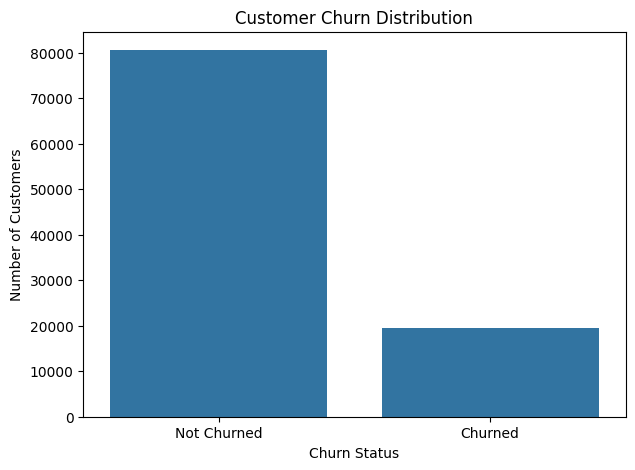

In [65]:
plt.figure(figsize=(7, 5))

sns.countplot(data=df, x='churned')

plt.title('Customer Churn Distribution')
plt.xlabel('Churn Status')
plt.ylabel('Number of Customers')

plt.xticks([0, 1], ['Not Churned', 'Churned'])

plt.show()

In [66]:
df['churned'].value_counts(normalize=True) * 100

,proportion
churned,
0,80.542
1,19.458


In [67]:
gender_churn = df.groupby('gender')['churned'].agg(
    ['count', 'sum', 'mean']
)

gender_churn.columns = [
    'Total Customers',
    'Churned Customers',
    'Churn Rate'
]

gender_churn['Churn Rate'] *= 100

print(gender_churn)

        Total Customers  Churned Customers  Churn Rate
gender                                                
Female            49193               9558   19.429594
Male              48794               9503   19.475755
Other              2013                397   19.721808


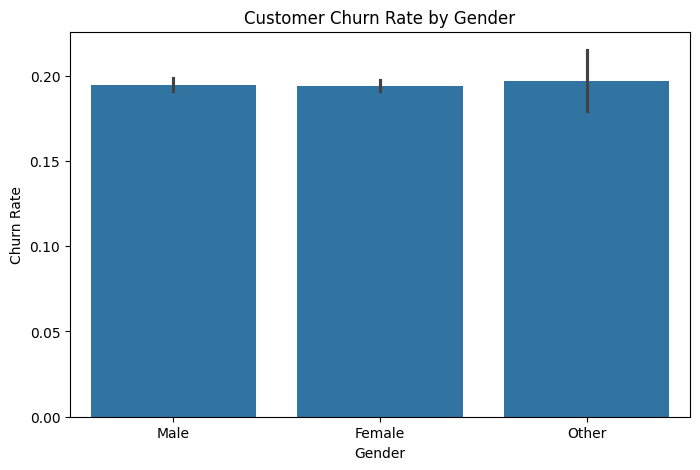

In [68]:
plt.figure(figsize=(8, 5))

sns.barplot(data=df, x='gender', y='churned')

plt.title('Customer Churn Rate by Gender')
plt.xlabel('Gender')
plt.ylabel('Churn Rate')

plt.show()

In [69]:
#churn by Age group
bins = [0,25,35,45,60,100]
labels = [
    '18-25',
    '26-35',
    '36-45',
    '46-60',
    'Above 60'
]
df['age_group'] = pd.cut(
    df['age'],
    bins=bins,
    labels=labels
)

In [70]:
age_churn = df.groupby(
    'age_group',
    observed=True
)['churned'].agg(['count', 'sum', 'mean'])

age_churn.columns = [
    'Total Customers',
    'Churned Customers',
    'Churn Rate'
]

age_churn['Churn Rate'] *= 100

print(age_churn)

           Total Customers  Churned Customers  Churn Rate
age_group                                                
18-25                 8261               1602   19.392325
26-35                18615               3587   19.269406
36-45                29248               5678   19.413293
46-60                34261               6701   19.558682
Above 60              9615               1890   19.656786


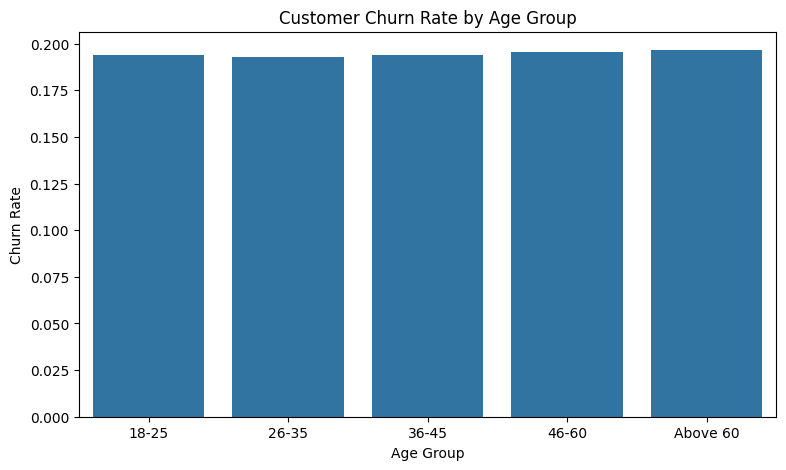

In [71]:
plt.figure(figsize=(9, 5))

sns.barplot(
    data=df,
    x='age_group',
    y='churned',
    errorbar=None
)

plt.title('Customer Churn Rate by Age Group')
plt.xlabel('Age Group')
plt.ylabel('Churn Rate')

plt.show()

In [72]:
#churn by card type
card_churn = df.groupby('card_type')['churned'].agg(
    ['count', 'sum', 'mean']
)

card_churn.columns = [
    'Total Customers',
    'Churned Customers',
    'Churn Rate'
]

card_churn['Churn Rate'] *= 100

print(card_churn)

           Total Customers  Churned Customers  Churn Rate
card_type                                                
Gold                 18061               3476   19.245889
Platinum              7123               1348   18.924610
Silver               29768               5785   19.433620
Standard             45048               8849   19.643491


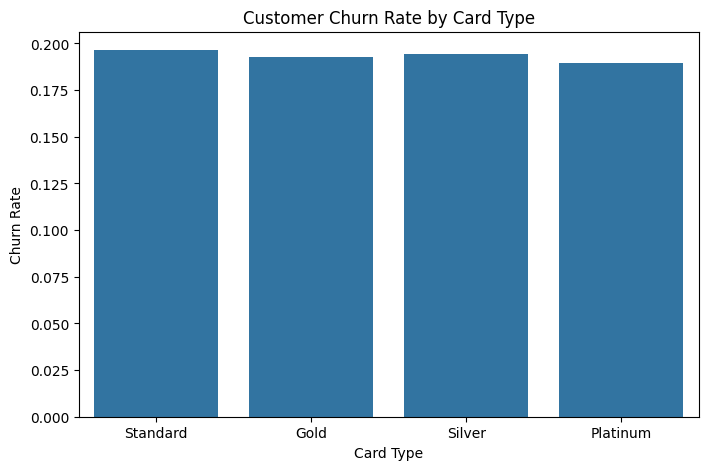

In [73]:
plt.figure(figsize=(8, 5))

sns.barplot(
    data=df,
    x='card_type',
    y='churned',
    errorbar=None
)

plt.title('Customer Churn Rate by Card Type')
plt.xlabel('Card Type')
plt.ylabel('Churn Rate')

plt.show()

In [74]:
df['income_group'] = pd.qcut(
    df['income'],
    q=4,
    labels=['Low Income', 'Lower-Middle',
            'Upper-Middle', 'High Income']
)

In [75]:
income_churn = df.groupby(
    'income_group',
    observed=True
)['churned'].agg(['count', 'sum', 'mean'])

income_churn.columns = [
    'Total Customers',
    'Churned Customers',
    'Churn Rate'
]

income_churn['Churn Rate'] *= 100

print(income_churn)

              Total Customers  Churned Customers  Churn Rate
income_group                                                
Low Income              25000               4922      19.688
Lower-Middle            25000               4793      19.172
Upper-Middle            25000               4938      19.752
High Income             25000               4805      19.220


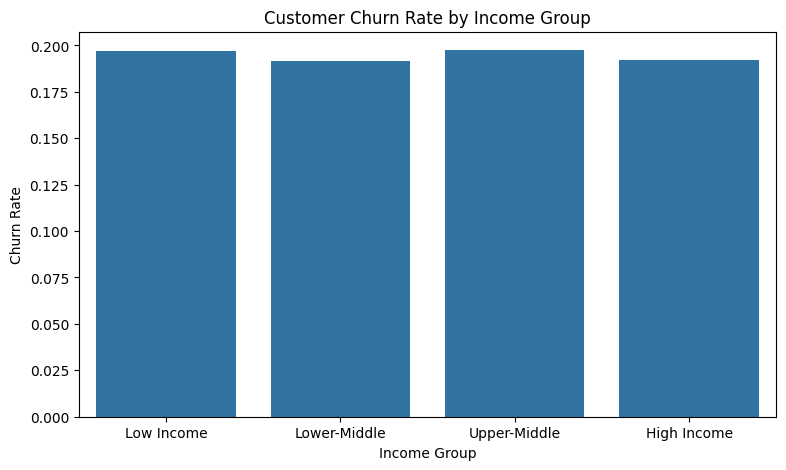

In [76]:
plt.figure(figsize=(9, 5))

sns.barplot(
    data=df,
    x='income_group',
    y='churned',
    errorbar=None
)

plt.title('Customer Churn Rate by Income Group')
plt.xlabel('Income Group')
plt.ylabel('Churn Rate')

plt.show()

In [77]:
#churn by payment
payment_churn = df.groupby(
    'payment_delay_count'
)['churned'].agg(['count', 'sum', 'mean'])

payment_churn.columns = [
    'Total Customers',
    'Churned Customers',
    'Churn Rate'
]

payment_churn['Churn Rate'] *= 100

print(payment_churn)

                     Total Customers  Churned Customers  Churn Rate
payment_delay_count                                                
0                              70059               8728   12.458071
1                              20785               5621   27.043541
2                               6496               3087   47.521552
3                               1871               1317   70.390166
4                                546                474   86.813187
5                                182                171   93.956044
6                                 41                 40   97.560976
7                                 12                 12  100.000000
8                                  7                  7  100.000000
9                                  1                  1  100.000000


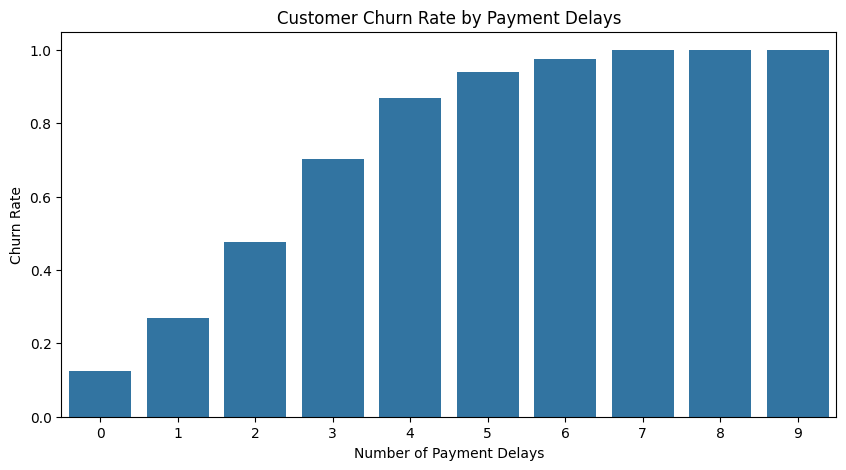

In [78]:
plt.figure(figsize=(10, 5))

sns.barplot(
    data=df,
    x='payment_delay_count',
    y='churned',
    errorbar=None
)

plt.title('Customer Churn Rate by Payment Delays')
plt.xlabel('Number of Payment Delays')
plt.ylabel('Churn Rate')

plt.show()

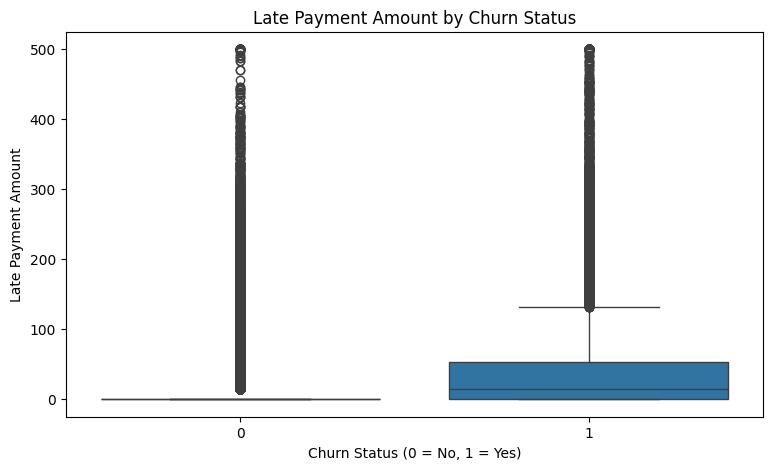

In [79]:
plt.figure(figsize=(9, 5))

sns.boxplot(
    data=df,
    x='churned',
    y='late_payment_amount'
)

plt.title('Late Payment Amount by Churn Status')
plt.xlabel('Churn Status (0 = No, 1 = Yes)')
plt.ylabel('Late Payment Amount')

plt.show()

In [80]:
payment_check = df.groupby('payment_delay_count')['churned'].agg(
    Total_Customers='count',
    Churned_Customers='sum',
    Churn_Rate='mean'
)

payment_check['Churn_Rate'] *= 100

print(payment_check)

                     Total_Customers  Churned_Customers  Churn_Rate
payment_delay_count                                                
0                              70059               8728   12.458071
1                              20785               5621   27.043541
2                               6496               3087   47.521552
3                               1871               1317   70.390166
4                                546                474   86.813187
5                                182                171   93.956044
6                                 41                 40   97.560976
7                                 12                 12  100.000000
8                                  7                  7  100.000000
9                                  1                  1  100.000000


In [81]:
df.groupby('churned')['late_payment_amount'].agg(
    ['count', 'mean', 'median', 'max']
)

,count,mean,median,max
churned,,,,
0,80542,13.999991,0.0,500.0
1,19458,43.349281,15.0,500.0


In [82]:
df['engagement_group'] = pd.cut(
    df['engagement_score'],
    bins=[0, 25, 50, 75, 100],
    labels=['Low', 'Medium', 'High', 'Very High'],
    include_lowest=True
)

In [83]:
engagement_churn = df.groupby(
    'engagement_group',
    observed=True
)['churned'].agg(['count', 'sum', 'mean'])

engagement_churn.columns = [
    'Total Customers',
    'Churned Customers',
    'Churn Rate'
]

engagement_churn['Churn Rate'] *= 100

print(engagement_churn)

                  Total Customers  Churned Customers  Churn Rate
engagement_group                                                
Low                           155                 85   54.838710
Medium                      16795               5483   32.646621
High                        56697              11297   19.925217
Very High                   26353               2593    9.839487


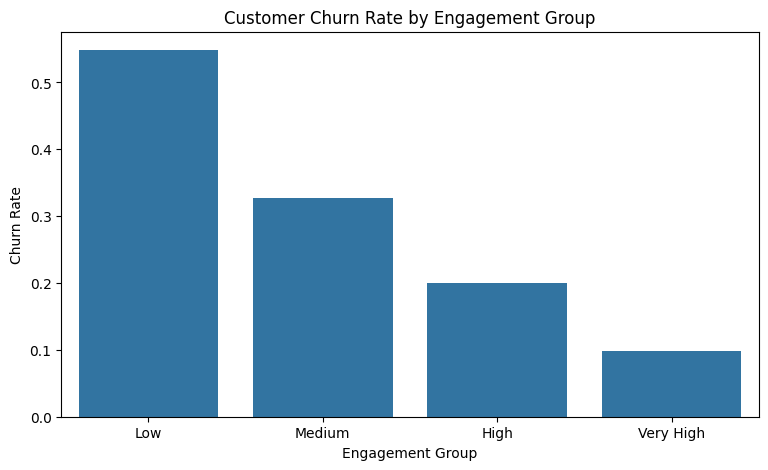

In [84]:
plt.figure(figsize=(9, 5))

sns.barplot(
    data=df,
    x='engagement_group',
    y='churned',
    errorbar=None
)

plt.title('Customer Churn Rate by Engagement Group')
plt.xlabel('Engagement Group')
plt.ylabel('Churn Rate')

plt.show()

In [85]:
service_churn = df.groupby('customer_service_calls')['churned'].agg(
    ['count', 'sum', 'mean']
)

service_churn.columns = [
    'Total Customers',
    'Churned Customers',
    'Churn Rate'
]

service_churn['Churn Rate'] *= 100

print(service_churn)

                        Total Customers  Churned Customers  Churn Rate
customer_service_calls                                                
0                                 39947               5505   13.780760
1                                 23873               4032   16.889373
2                                 14482               3033   20.943240
3                                  8650               2181   25.213873
4                                  5265               1536   29.173789
5                                  3151               1074   34.084418
6                                  1802                690   38.290788
7                                  1161                509   43.841516
8                                   715                353   49.370629
9                                   398                199   50.000000
10                                  217                121   55.760369
11                                  128                 72   56.250000
12    

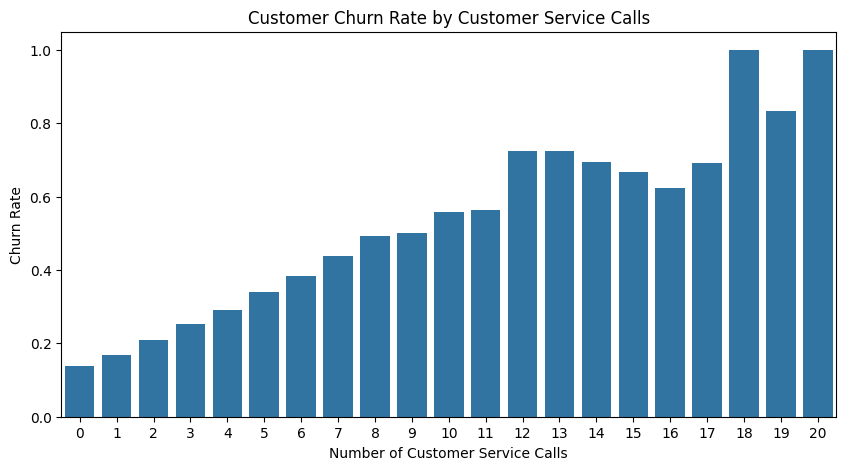

In [86]:
plt.figure(figsize=(10, 5))

sns.barplot(
    data=df,
    x='customer_service_calls',
    y='churned',
    errorbar=None
)

plt.title('Customer Churn Rate by Customer Service Calls')
plt.xlabel('Number of Customer Service Calls')
plt.ylabel('Churn Rate')

plt.show()

In [87]:
service_check = df.groupby('customer_service_calls')['churned'].agg(
    Total_Customers='count',
    Churned_Customers='sum',
    Churn_Rate='mean'
)

service_check['Churn_Rate'] *= 100

print(service_check)

                        Total_Customers  Churned_Customers  Churn_Rate
customer_service_calls                                                
0                                 39947               5505   13.780760
1                                 23873               4032   16.889373
2                                 14482               3033   20.943240
3                                  8650               2181   25.213873
4                                  5265               1536   29.173789
5                                  3151               1074   34.084418
6                                  1802                690   38.290788
7                                  1161                509   43.841516
8                                   715                353   49.370629
9                                   398                199   50.000000
10                                  217                121   55.760369
11                                  128                 72   56.250000
12    

In [88]:
satisfaction = df.groupby('churned')['support_satisfaction'].agg(
    ['count', 'mean', 'median']
)

print(satisfaction)

         count      mean  median
churned                         
0        80542  3.586326     3.7
1        19458  2.910088     3.0


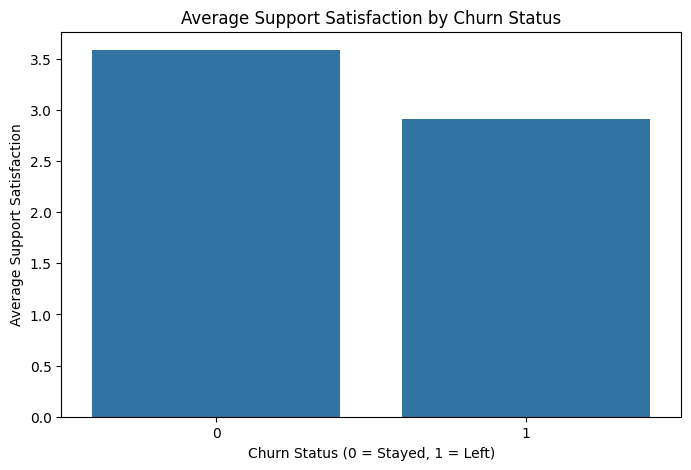

In [89]:
plt.figure(figsize=(8, 5))

sns.barplot(
    data=df,
    x='churned',
    y='support_satisfaction',
    errorbar=None
)

plt.title('Average Support Satisfaction by Churn Status')
plt.xlabel('Churn Status (0 = Stayed, 1 = Left)')
plt.ylabel('Average Support Satisfaction')

plt.show()

In [90]:
complaint_churn = df.groupby('complaints_count')['churned'].agg(
    ['count', 'sum', 'mean']
)

complaint_churn.columns = [
    'Total Customers',
    'Churned Customers',
    'Churn Rate'
]

complaint_churn['Churn Rate'] *= 100

print(complaint_churn)

                  Total Customers  Churned Customers  Churn Rate
complaints_count                                                
0                           62355               8583   13.764734
1                           23439               5199   22.180980
2                            8760               2859   32.636986
3                            3407               1535   45.054300
4                            1320                758   57.424242
5                             457                307   67.177243
6                             158                126   79.746835
7                              61                 53   86.885246
8                              29                 24   82.758621
9                               9                  9  100.000000
10                              4                  4  100.000000
13                              1                  1  100.000000


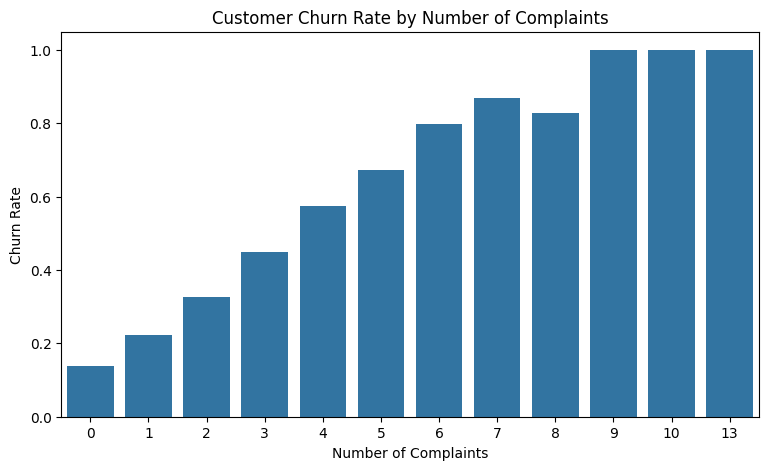

In [91]:
plt.figure(figsize=(9, 5))

sns.barplot(
    data=df,
    x='complaints_count',
    y='churned',
    errorbar=None
)

plt.title('Customer Churn Rate by Number of Complaints')
plt.xlabel('Number of Complaints')
plt.ylabel('Churn Rate')

plt.show()

In [92]:
complaint_check = df.groupby('complaints_count')['churned'].agg(
    Total_Customers='count',
    Churned_Customers='sum',
    Churn_Rate='mean'
)

complaint_check['Churn_Rate'] *= 100

print(complaint_check)

                  Total_Customers  Churned_Customers  Churn_Rate
complaints_count                                                
0                           62355               8583   13.764734
1                           23439               5199   22.180980
2                            8760               2859   32.636986
3                            3407               1535   45.054300
4                            1320                758   57.424242
5                             457                307   67.177243
6                             158                126   79.746835
7                              61                 53   86.885246
8                              29                 24   82.758621
9                               9                  9  100.000000
10                              4                  4  100.000000
13                              1                  1  100.000000


In [93]:
city_churn = df.groupby('city')['churned'].agg(
    ['count', 'sum', 'mean']
)

city_churn.columns = [
    'Total Customers',
    'Churned Customers',
    'Churn Rate'
]

city_churn['Churn Rate'] *= 100

print(city_churn.sort_values('Churn Rate', ascending=False))

              Total Customers  Churned Customers  Churn Rate
city                                                        
San Diego                3984                788   19.779116
Los Angeles             10021               1972   19.678675
Other                   42047               8239   19.594739
Philadelphia             4965                967   19.476334
Phoenix                  5027                979   19.474836
Chicago                  8126               1582   19.468373
New York                11832               2294   19.388100
Dallas                   3975                755   18.993711
Houston                  6015               1131   18.802993
San Antonio              4008                751   18.737525


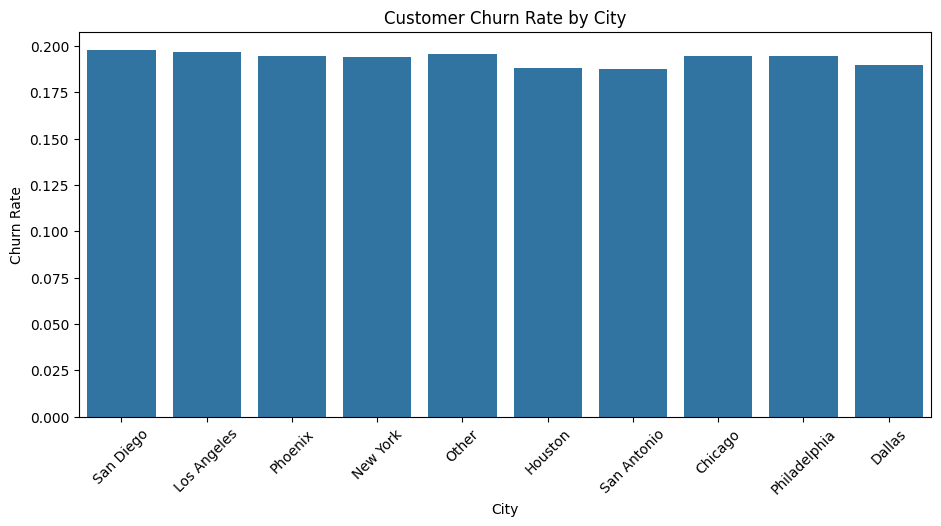

In [94]:
plt.figure(figsize=(11, 5))

sns.barplot(
    data=df,
    x='city',
    y='churned',
    errorbar=None
)

plt.title('Customer Churn Rate by City')
plt.xlabel('City')
plt.ylabel('Churn Rate')
plt.xticks(rotation=45)

plt.show()

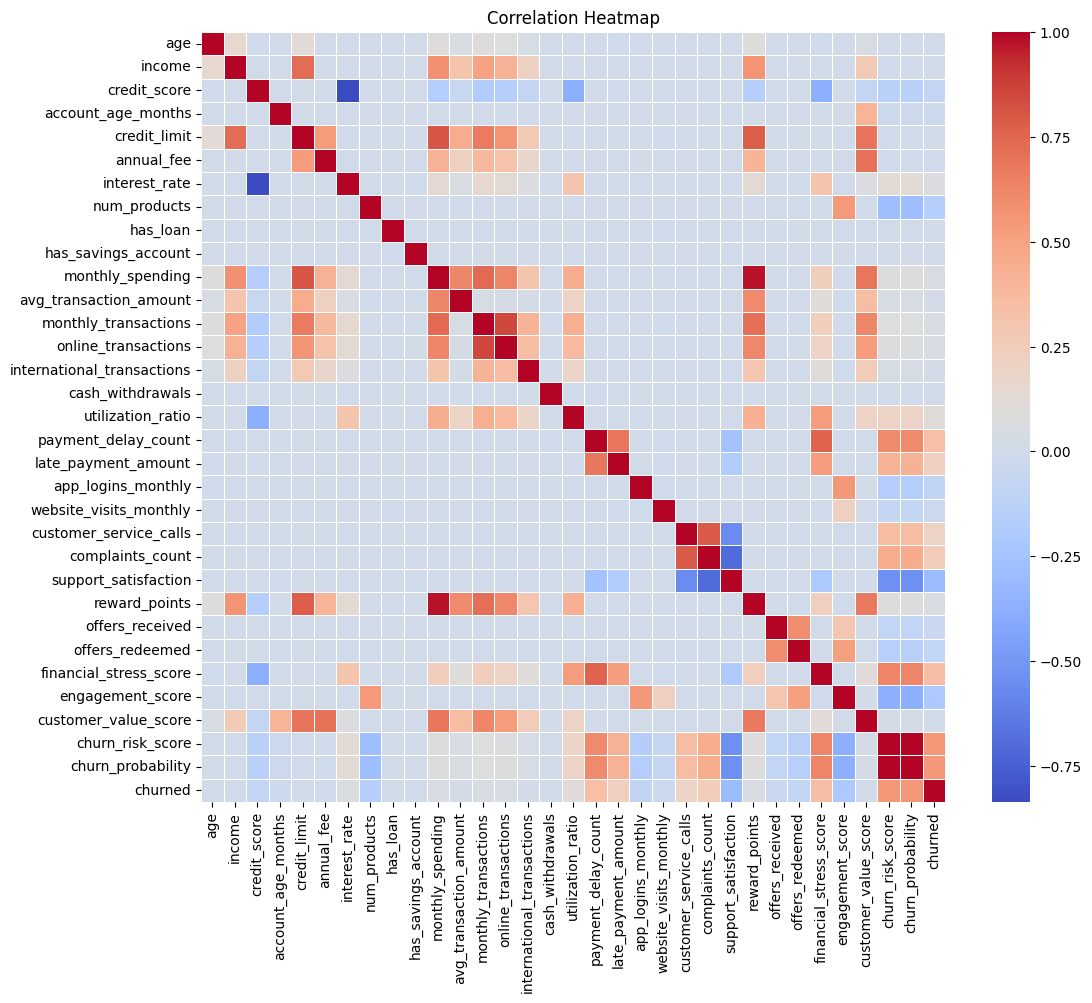

In [95]:
plt.figure(figsize=(12, 10))

corr = df.corr(numeric_only=True)

sns.heatmap(
    corr,
    cmap='coolwarm',
    annot=False,
    linewidths=0.5
)

plt.title('Correlation Heatmap')
plt.show()

In [96]:
churn_corr = corr['churned'].sort_values(
    ascending=False
)

print(churn_corr)

churned                       1.000000
churn_risk_score              0.554211
churn_probability             0.554211
financial_stress_score        0.348089
payment_delay_count           0.340693
complaints_count              0.250736
late_payment_amount           0.230523
customer_service_calls        0.200247
utilization_ratio             0.110509
interest_rate                 0.065118
monthly_spending              0.049658
reward_points                 0.048286
monthly_transactions          0.045758
online_transactions           0.040835
avg_transaction_amount        0.024865
international_transactions    0.017647
customer_value_score          0.010066
has_loan                      0.002540
age                           0.002241
has_savings_account           0.001594
credit_limit                 -0.001580
cash_withdrawals             -0.002062
income                       -0.002510
annual_fee                   -0.004999
account_age_months           -0.018391
website_visits_monthly   

In [97]:
difference = (
    df['churn_risk_score'] -
    df['churn_probability'] * 100
)

print("Maximum Difference:", difference.abs().max())

Maximum Difference: 1.4210854715202004e-14


In [98]:
df.groupby('churned')[
    ['churn_risk_score', 'churn_probability']
].mean()

,churn_risk_score,churn_probability
churned,,
0,13.498745,0.134987
1,44.134260,0.441343


In [99]:
print(pd.crosstab(
    df['churned'],
    df['churn_probability'] >= 0.5
))

churn_probability  False  True 
churned                        
0                  77326   3216
1                  11623   7835


In [100]:
df.to_csv('cleaned_customer_churn.csv', index=False)

In [101]:
from google.colab import files

files.download('cleaned_customer_churn.csv')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>